In [2]:
import torch
import torch.nn.functional as F

import numpy as np
import scipy
import matplotlib.pyplot as plt
from matplotlib import colors
import math

import pandas as pd
from torch_tps import ThinPlateSpline

In [3]:
import sys, os, importlib

import brack2bing
importlib.reload(brack2bing)

if (os.path.exists("brack2bing_solver_cache/init.pickle")):
    icesim = brack2bing.LatticeSolver.load()
else:
    icesim = brack2bing.LatticeSolver(device='cuda')
    icesim.save()

import resice_data
importlib.reload(resice_data)
T,S,rho = resice_data.get_scaled_cores(bins=30, device='cuda', min_samples=4, max_depth=3)

lattice = icesim.gen_lattice(T,S,rho)
er = icesim.get_dielectric(lattice, T[:,None,None,None,:], 1.2)

In [212]:
er[0].mean()

tensor(46.7115-11.8752j, device='cuda:0')

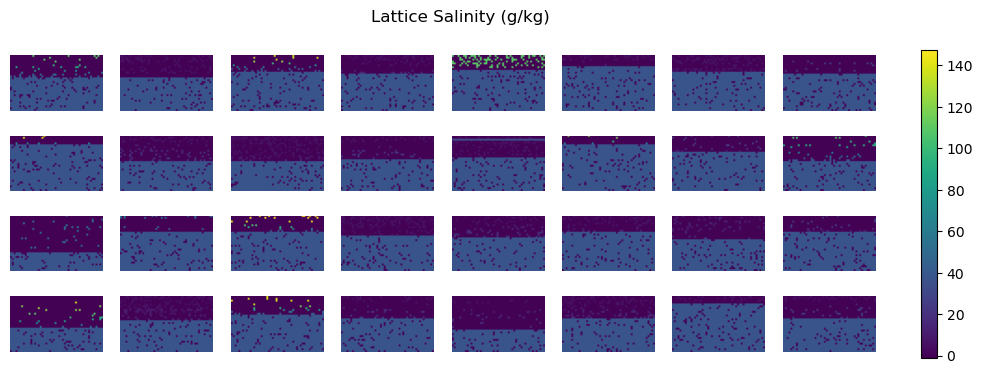

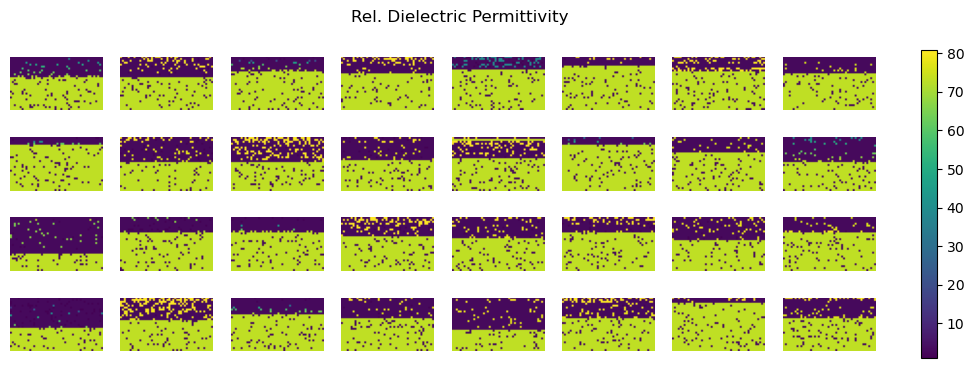

In [19]:
# -- plot lattice salinity
fig, axs = plt.subplots(4, 8, figsize=(12,4)); plt.axis('off');
tmp = lattice[:,0,25,1:-1,1:-1].cpu(); tmpmm = (tmp.min(), tmp.max())
norm = colors.Normalize(vmin=tmp.min(), vmax=tmp.max())
images = [axs.flat[i].imshow(tmp[i].T,norm=norm) for i in range(min(32, lattice.shape[0]))]; [axs.flat[i].set_axis_off() for i in range(32)];
fig.suptitle('Lattice Salinity (g/kg)'); fig.colorbar(images[0], ax=axs, orientation='vertical', fraction=.02)
fig.savefig('image1.jpg')

# -- plot lattice e_r
fig, axs = plt.subplots(4, 8, figsize=(12,4)); plt.axis('off');
tmp = er[:,0,25,1:-1,1:-1].real.cpu(); tmpmm = (tmp.min(), tmp.max())
norm = colors.Normalize(vmin=tmp.min(), vmax=tmp.max())
images = [axs.flat[i].imshow(tmp[i].T,norm=norm) for i in range(min(32, lattice.shape[0]))]; [axs.flat[i].set_axis_off() for i in range(32)]
fig.suptitle('Rel. Dielectric Permittivity'); fig.colorbar(images[0], ax=axs, orientation='vertical', fraction=.02)
fig.savefig('image2.jpg')

In [259]:
import LBM4S_v0
importlib.reload(LBM4S_v0)
torch.cuda.empty_cache()

# -- run simulations for each lattice

result = []
read, driver, kI = LBM4S_v0.simulate(er[0,None], cells_per_m=10, pol='H', n_periods=5, inc=(0,0), verbose=True, dtype=torch.float32, periodic=(0,1))
result.append(LBM4S_v0.get_scat_coeff(read, driver, kI, single_pixel=True, ignore_H=True))

0.096556035677591950.01 min


In [187]:
from LBM4Scatter import LBM4S_main
read, driver, kI = LBM4S_main.simulate(er[0,None], cells_per_m=10, pol='H', n_periods=5, inc=(0,0), verbose=True, dtype=torch.float32, floquet=(0,1))

0.098555227120717360.01 min


In [261]:
read.shape

torch.Size([1, 1, 546, 50, 50, 3, 2])

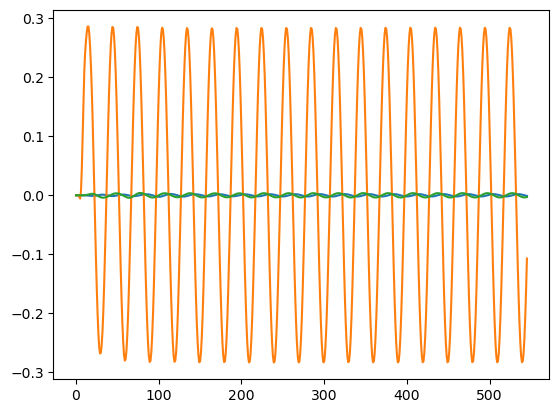

In [266]:
plt.plot(read[0,0].mean(dim=(1,2))[...,0].cpu())

In [178]:
read.shape

torch.Size([1, 1, 546, 50, 50, 6])

In [80]:
refl = result[0]
(B,C,X,Y,Z), dtype = er.shape, er.real.dtype
thickness = (torch.abs(er).mean(dim=(-2,-3)) < 50).to(dtype).mean(dim=-1) * Z/10

In [74]:
#plt.scatter(thickness.flatten().cpu(), refl.abs()[...,1].flatten().cpu(), -10*T.max(dim=-1)[0].cpu())

In [109]:
refl_fit = torch.stack((refl.real, refl.imag),dim=-1).flatten(0,1).flatten(1)
para_fit = torch.stack((thickness.flatten(), T.max(dim=-1)[0]),dim=-1)

In [144]:
np.isscalar(torch.tensor([1], device='cuda')[0])

False

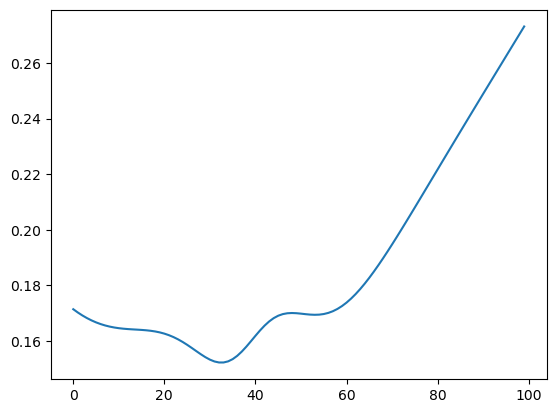

In [131]:
tps_tmp = ThinPlateSpline(alpha=0.02, order=1)
tps_tmp.fit(para_fit, refl_fit)
sample = torch.stack((torch.linspace(0,3,100), -1*torch.ones(100)),dim=-1)
tmp = tps_tmp.transform(sample).view(100, refl.shape[-1], 2)

tmp = torch.complex(tmp[...,0], tmp[...,1])
plt.plot(tmp.cpu().abs()[:,1])